# Quasinormal modes of a charged scalar field around a Reissner–Nordström black hole

Corrected and extended version of the numerical part of `reissner_nordstrom_background.ipynb`.

**Setup.** Ingoing Eddington–Finkelstein coordinates with compactified radius $u = 1/r$; the event horizon sits at $u=1$ ($r_+=1$):

$$ds^2 = -f(u)\,dv^2 - \frac{2}{u^2}\,dv\,du + \frac{1}{u^2}\,d\Omega^2,\qquad f(u) = (1-u)(1-q\,u),\qquad q = r_-/r_+ .$$

The Maxwell field is $A = Q_b\,(u-1)\,dv$, and the scalar carries charge $e$, so it couples through $eA_v = c\,(u-1)$ with $c = eQ_b$. In the conventions of the background notebook ($\kappa = 1$), $q = Q_b^2/2$ and $c = Q_b^2$ when $e = Q_b$. Mass and charge in geometric units: $M = (1+q)/2$, $Q/M = 2\sqrt q/(1+q)$; extremality is $q = 1$.

In [1]:
import numpy as np, sympy as sp, scipy.linalg as la, matplotlib.pyplot as plt
u, w, q, c, L2 = sp.symbols('u omega q c L2')

## 1. Radial equation

The charged Klein–Gordon equation is $\frac{1}{\sqrt{-g}}D_\mu\!\left(\sqrt{-g}\,g^{\mu\nu}D_\nu\Phi\right)=0$ with $D_\mu = \partial_\mu + ieA_\mu$. The $\sqrt{-g}$ factors matter: they produce the $f'(u)$ term and the extra first-order terms. Contracting $g^{\mu\nu}$ with plain second derivatives drops them, and that omission was the main error in the original version.

With $\sqrt{-g}=\sin\theta/u^4$, $g^{vu}=-u^2$, $g^{uu}=u^4 f$ and $\Phi = e^{-i\omega v} R(u)\, Y_{\ell m}$, the local frequency is $\varpi(u) = \omega - c\,(u-1)$, and the equation becomes

$$u^4 f R'' + u^4 f' R' + 2i\varpi u^2 R' - \left(i c\,u^2 + 2i\varpi\,u + \ell(\ell+1)\,u^2\right) R = 0 .$$

For $c=0$, $q=0$ this is exactly the Schwarzschild equation of `schwarzschild_scalar_EF.ipynb`.

In [2]:
f  = (1 - u) * (1 - q*u)
vp = w - c*(u - 1)
R  = sp.Function('R')(u)
radial = u**4*f*R.diff(u,2) + u**4*f.diff(u)*R.diff(u) + 2*sp.I*vp*u**2*R.diff(u) \
         - (sp.I*c*u**2 + 2*sp.I*vp*u + L2*u**2)*R
radial

u**4*(1 - u)*(-q*u + 1)*Derivative(R(u), (u, 2)) + u**4*(q*u - q*(1 - u) - 1)*Derivative(R(u), u) + 2*I*u**2*(-c*(u - 1) + omega)*Derivative(R(u), u) - (L2*u**2 + I*c*u**2 + 2*I*u*(-c*(u - 1) + omega))*R(u)

## 2. Boundary conditions

* **Horizon ($u=1$).** The local exponents are $0$ and $2 - 2i\omega/(1-q)$. In ingoing coordinates the physical, infalling solution is the regular one, with exponent $0$.
* **Infinity ($u\to0$).** $R \sim e^{\alpha/u}u^{\beta}$. The leading order gives $\alpha^2 - 2i(\omega+c)\alpha = 0$, and the outgoing branch is $\alpha = 2i(\omega + c)$. The next order fixes $\beta$.

In [3]:
al, be = sp.symbols('alpha beta')
psi = sp.Function('psi')(u)
E = sp.expand(sp.powsimp(sp.expand(radial.subs(R, sp.exp(al/u)*u**be*psi).doit()
                                   / (sp.exp(al/u)*u**be)), force=True))
k0 = sp.expand((E - E.coeff(psi.diff(u,2))*psi.diff(u,2) - E.coeff(psi.diff(u))*psi.diff(u)) / psi)
lead = sp.factor(sp.limit(k0, u, 0))   # leading behaviour at infinity
print('leading order :', lead, '->', sp.solve(lead, al))
alpha_out = 2*sp.I*(w + c)
nxt = sp.expand(k0.subs(al, alpha_out))
coef_u1 = sp.expand(nxt).coeff(u, 1)
beta_sol = sp.solve(coef_u1, be)[0]
print('beta =', sp.simplify(beta_sol))

leading order : -I*alpha*(I*alpha + 2*c + 2*omega) -> [0, 2*I*(c + omega)]
beta = -2*I*c*q - 2*I*omega*q - 2*I*omega + 1


## 3. Regular equation and spectral discretisation

With $R = e^{\alpha/u}u^{\beta}\psi(u)$ and the values above, dividing by $u^2$ leaves an equation with **polynomial** coefficients that is quadratic in $\omega$:

$$\left(A_0 + \omega A_1 + \omega^2 A_2\right)\psi = 0 .$$

The coefficient of $\psi''$ vanishes at both ends, so a Chebyshev collocation automatically selects the regular, physical solution, and no extra boundary rows are needed. The quadratic eigenvalue problem is linearised to a $2(N+1)$ generalised eigenvalue problem.

In [4]:
Rsub = sp.exp(alpha_out/u) * u**beta_sol * psi
E = sp.expand(sp.powsimp(sp.expand(radial.subs(R, Rsub).doit() / (sp.exp(alpha_out/u)*u**beta_sol)), force=True))
E = sp.expand(E / u**2)
d2, d1 = psi.diff(u,2), psi.diff(u)
K = {2: sp.expand(E.coeff(d2)), 1: sp.expand(E.coeff(d1))}
K[0] = sp.expand((E - K[2]*d2 - K[1]*d1)/psi)
coeffs = {(k, p): sp.Poly(K[k], w).coeff_monomial(w**p) for k in K for p in range(3)}
for k in (2, 1, 0):
    print(f"psi^({k}) :", [sp.factor(coeffs[(k, p)]) for p in range(3)])

psi^(2) : [u**2*(u - 1)*(q*u - 1), 0, 0]
psi^(1) : [-I*(4*c*q**2*u**3 - 4*c*q**2*u**2 - 2*c*u + 2*c + 4*I*q*u**3 - 3*I*q*u**2 - 3*I*u**2 + 2*I*u), -2*I*(2*q**2*u**3 - 2*q**2*u**2 + 2*q*u**3 - 2*q*u**2 - 2*u**2 + 1), 0]


psi^(0) : [-L2 - 4*c**2*q**3*u**2 + 4*c**2*q**3*u - 4*c**2*q**2*u + 4*c**2*q**2 - 6*I*c*q**2*u**2 + 4*I*c*q**2*u + I*c + 2*q*u**2 - q*u - u, -2*(4*c*q**3*u**2 - 4*c*q**3*u + 4*c*q**2*u**2 - 4*c*q**2 - 2*c*q - 2*c + 3*I*q**2*u**2 - 2*I*q**2*u + 3*I*q*u**2 - 2*I*q*u - 2*I*u), -4*(q*u + u + 1)*(q**2*u - q**2 + q*u - q - 1)]


In [5]:
def cheb(N):
    x = np.cos(np.pi*np.arange(N+1)/N)
    cc = np.r_[2, np.ones(N-1), 2] * (-1)**np.arange(N+1)
    X = np.tile(x, (N+1, 1)).T
    D = np.outer(cc, 1/cc) / (X - X.T + np.eye(N+1))
    return x, D - np.diag(D.sum(axis=1))

def spectrum(qv, cv, l, N):
    x, D = cheb(N); ug = (x + 1)/2
    ops = {2: 4*D@D, 1: 2*D, 0: np.eye(N+1)}
    M = []
    for p in range(3):
        Mp = np.zeros((N+1, N+1), complex)
        for k, Dk in ops.items():
            fn = sp.lambdify(u, coeffs[(k, p)].subs({q: qv, c: cv, L2: l*(l+1)}), 'numpy')
            Mp += np.diag(np.broadcast_to(np.asarray(fn(ug), complex), ug.shape)) @ Dk
        M.append(Mp)
    n = N + 1; Z, I = np.zeros((n, n)), np.eye(n)
    ev = la.eig(np.block([[Z, I], [-M[0], -M[1]]]), np.block([[I, Z], [Z, M[2]]]), right=False)
    return ev[np.isfinite(ev)]

def converged(qv, cv, l, N1=50, N2=70, tol=1e-6):
    """Keep only eigenvalues that agree between two resolutions; the rest are discretisation artefacts."""
    a, b = spectrum(qv, cv, l, N1), spectrum(qv, cv, l, N2)
    b = b[abs(b) < 60]
    ok = np.array([np.min(abs(a - z)) < tol for z in b])
    return b[ok], b[~ok]

## 4. Validation: Schwarzschild limit

For $q = c = 0$ the code must reproduce the well-known $\ell = 2$ scalar modes $M\omega = 0.48364 - 0.09677i$ (fundamental) and $0.46385 - 0.29560i$ (first overtone).

In [6]:
good, _ = converged(0, 0, 2)
M = 0.5
for z in sorted(good[good.real > 0], key=lambda z: -z.imag):
    print(f"M*omega = {z.real*M:.5f} {z.imag*M:+.5f}i")

M*omega = 0.48364 -0.09676i
M*omega = 0.46385 -0.29560i


## 5. Charged black hole and charged field

Parameters of the original notebook: $Q_b = 1$, $\kappa = 1$, $e = Q_b$, so $q = 0.5$ and $c = 1$ ($Q/M \approx 0.94$, close to extremal).

Schwarzschild (Q = 0)  M*omega = -0.48364 -0.09676i
Schwarzschild (Q = 0)  M*omega = +0.48364 -0.09676i
Schwarzschild (Q = 0)  M*omega = -0.46385 -0.29560i
Schwarzschild (Q = 0)  M*omega = +0.46385 -0.29560i


Reissner–Nordström, charged scalar M*omega = -0.96820 -0.06887i
Reissner–Nordström, charged scalar M*omega = +0.37529 -0.09863i
Reissner–Nordström, charged scalar M*omega = +0.36913 -0.29599i


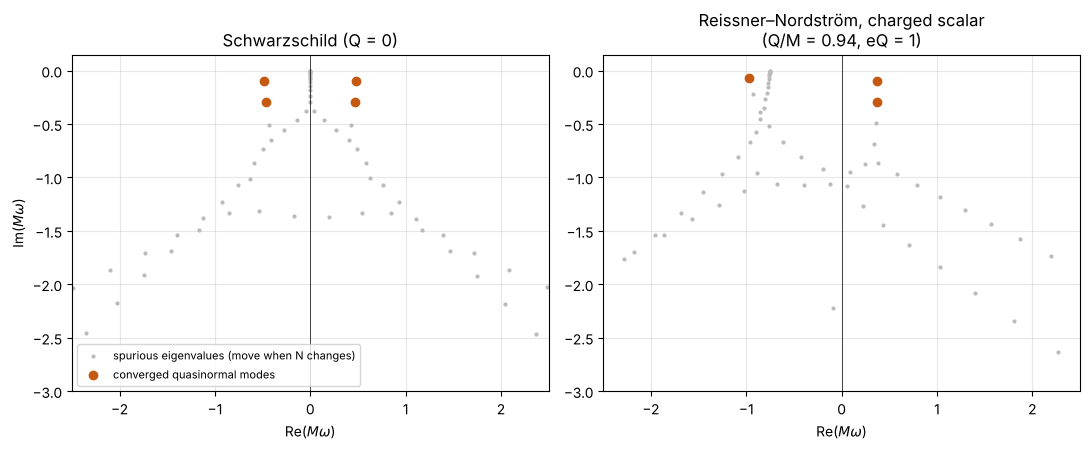

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for k, (qv, cv, title) in enumerate([(0, 0, 'Schwarzschild (Q = 0)'),
                                     (0.5, 1, 'Reissner–Nordström, charged scalar\n(Q/M = 0.94, eQ = 1)')]):
    good, bad = converged(qv, cv, 2); M = (1 + qv)/2
    for z in sorted(good, key=lambda z: -z.imag):
        print(f"{title.splitlines()[0]:<22s} M*omega = {z.real*M:+.5f} {z.imag*M:+.5f}i")
    ax[k].plot(bad.real*M, bad.imag*M, '.', color='#bbbbbb', ms=4, label='spurious eigenvalues (move when N changes)')
    ax[k].plot(good.real*M, good.imag*M, 'o', color='#c45a12', ms=6, label='converged quasinormal modes')
    ax[k].set(xlim=(-2.5, 2.5), ylim=(-3, 0.15), xlabel=r'Re($M\omega$)', title=title)
    ax[k].axvline(0, c='k', lw=.5); ax[k].grid(alpha=.3)
ax[0].set_ylabel(r'Im($M\omega$)'); ax[0].legend(loc='lower left', fontsize=8)
plt.tight_layout(); plt.savefig('qnm_spectrum.png', dpi=150); plt.show()

* All converged modes have $\mathrm{Im}\,\omega<0$, so they decay and the black hole is stable against this perturbation.
* For a neutral field the spectrum is symmetric under $\omega \to -\omega^*$. The charge coupling **breaks this symmetry**: the two branches are shifted in opposite directions.
* The grey points come from the finite discretisation. The column of points near $\mathrm{Re}\,\omega = 0$ (Schwarzschild), or near $\omega r_+ = -c$ (charged case), is the discretised **branch cut** of the problem, not a set of modes. Only eigenvalues that are stable under a change of $N$ are physical.

## 6. Fundamental mode as a function of the black-hole charge

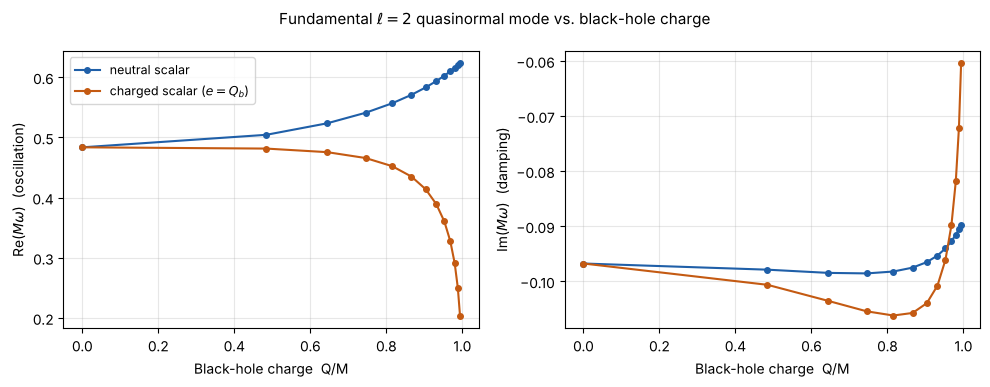

In [8]:
rows = []
for qv in np.linspace(0, 0.8, 13):
    M = (1 + qv)/2; QM = 2*np.sqrt(qv)/(1 + qv); r = [QM]
    for cv in (0.0, 2*qv):               # neutral field, and e = Q_b (c = Q_b^2 = 2q)
        good, _ = converged(qv, cv, 2)
        z = max(good[good.real > 0], key=lambda z: z.imag)
        r.append(z*M)
    rows.append(r)
rows = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.9))
for j, (lab, col) in enumerate([('neutral scalar', '#1f5fa8'), (r'charged scalar ($e = Q_b$)', '#c45a12')]):
    ax[0].plot(rows[:, 0].real, rows[:, j+1].real, 'o-', color=col, ms=4, label=lab)
    ax[1].plot(rows[:, 0].real, rows[:, j+1].imag, 'o-', color=col, ms=4, label=lab)
ax[0].set_ylabel(r'Re($M\omega$)  (oscillation)'); ax[1].set_ylabel(r'Im($M\omega$)  (damping)')
for a in ax: a.set_xlabel('Black-hole charge  Q/M'); a.grid(alpha=.3)
ax[0].legend(fontsize=9); fig.suptitle(r'Fundamental $\ell=2$ quasinormal mode vs. black-hole charge', fontsize=11)
plt.tight_layout(); plt.savefig('qnm_vs_charge.png', dpi=150); plt.show()

For a neutral field, increasing the charge raises the oscillation frequency, and the damping changes only slightly. For a charged field, the electrostatic interaction with the black hole lowers the frequency of the co-rotating branch strongly as the black hole approaches extremality.

## Notes on the corrections

Compared with the first version of this calculation:

1. The scalar equation now includes the $\sqrt{-g}$ (connection) terms of the covariant d'Alembertian.
2. The background function is $f = (1-u)(1 - Q_b^2u/2\kappa)$; the original code had a parenthesis error that multiplied by $\kappa$ instead of dividing.
3. The equation is made regular before discretisation, with coefficients that are polynomials in $u$. Previously, singular terms up to $u^{-5}$ were evaluated at $u=10^{-10}$, which filled the matrices with numbers of order $10^{50}$.
4. The matrices are built automatically from the symbolic coefficients instead of being transcribed by hand.
5. Converged modes are separated from spurious eigenvalues by comparing two resolutions.